# Exploración complementaria – tabla de colegios (Saber 11, 2020-2)

Este notebook responde a lo que el profesor señaló que faltó en la Entrega 1:

1. Distribución del puntaje promedio por colegio y del número de evaluados
2. Relación de **todas** las variables de contexto con el puntaje, a nivel de colegio (no solo el INSE)
3. Puntajes por área
4. En qué **regiones y tipos de establecimiento** se concentran los colegios por encima y por debajo de lo esperado

Todo se calcula sobre la tabla limpia `data/processed/colegios_2020_2.parquet` (una fila por colegio).
Las gráficas se guardan en `reports/figures/` para poder usarlas en el reporte.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Funciona tanto si el notebook se abre desde la raíz del repositorio como desde notebooks/
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

col = pd.read_parquet(RAIZ / "data" / "processed" / "colegios_2020_2.parquet")

PERFIL = {
    "inse_prom": "INSE promedio",
    "pct_madre_superior": "% madre con ed. superior",
    "pct_padre_superior": "% padre con ed. superior",
    "pct_estrato_1_2": "% estrato 1–2",
    "pct_estrato_5_6": "% estrato 5–6",
    "pct_internet": "% con internet",
    "pct_computador": "% con computador",
    "pct_libros_26mas": "% con más de 25 libros",
}
AREAS = {
    "punt_lectura_prom": "Lectura crítica",
    "punt_matematicas_prom": "Matemáticas",
    "punt_naturales_prom": "Ciencias naturales",
    "punt_sociales_prom": "Sociales y ciudadanas",
    "punt_ingles_prom": "Inglés",
}

AZUL, GRIS, VERDE, ROJO = "#2f6f9f", "#8a8f98", "#2e8b57", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=200, bbox_inches="tight")


print(f"{len(col):,} colegios y {col.shape[1]} columnas")

6,987 colegios y 23 columnas


## 1. Vista general

In [2]:
resumen = col[["n_evaluados", "punt_global_prom", *PERFIL]].describe().T
resumen[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,mean,std,min,25%,50%,75%,max
n_evaluados,67.11,54.43,20.00,31.00,50.00,85.00,831.00
punt_global_prom,247.04,31.96,162.46,224.63,243.52,265.32,370.69
inse_prom,50.40,7.22,32.60,45.05,49.29,54.64,74.74
pct_madre_superior,0.24,0.21,0.00,0.10,0.18,0.33,1.00
pct_padre_superior,0.20,0.19,0.00,0.07,0.13,0.25,0.97
pct_estrato_1_2,0.68,0.26,0.00,0.55,0.77,0.87,1.00
pct_estrato_5_6,0.02,0.07,0.00,0.00,0.00,0.02,0.89
pct_internet,0.66,0.29,0.00,0.44,0.73,0.92,1.00
pct_computador,0.58,0.27,0.00,0.36,0.58,0.82,1.00
pct_libros_26mas,0.27,0.17,0.00,0.15,0.22,0.34,1.00


## 2. Distribución del puntaje promedio y del número de evaluados por colegio

**Qué mirar:** si el puntaje tiene forma de campana o está cargado hacia un lado, y qué tan desigual es el tamaño de los colegios.
Un colegio con 20 evaluados tiene un promedio mucho más ruidoso que uno con 800.

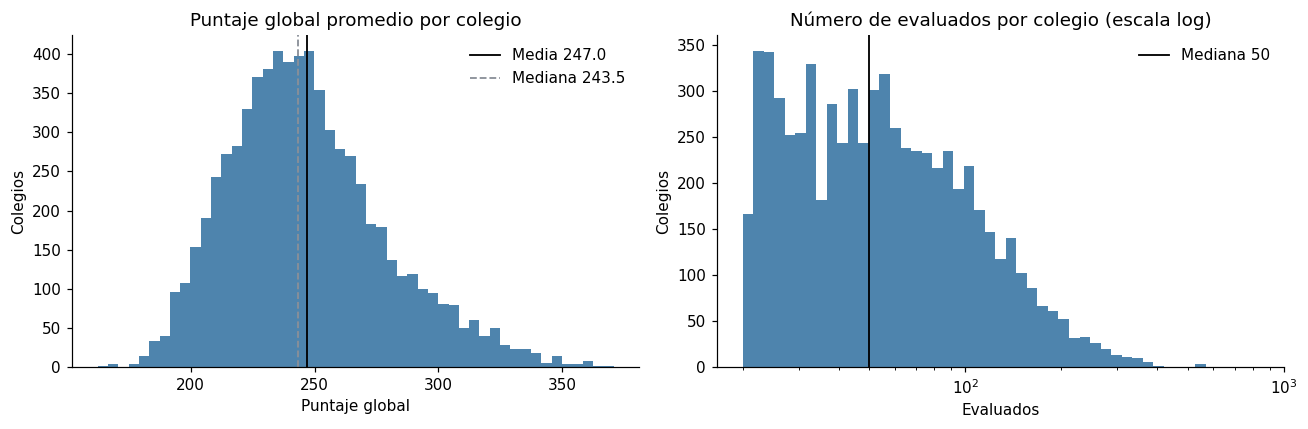

Puntaje global – percentiles 10/25/50/75/90: [209.3, 224.6, 243.5, 265.3, 291.4]
Asimetría del puntaje: 0.64  (positiva = cola hacia puntajes altos)
Evaluados – percentiles 10/25/50/75/90: [24, 31, 50, 85, 131]
Colegios con menos de 40 evaluados: 37.7%


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

p = col["punt_global_prom"]
ax[0].hist(p, bins=50, color=AZUL, alpha=0.85)
ax[0].axvline(p.mean(), color="black", lw=1.2, label=f"Media {p.mean():.1f}")
ax[0].axvline(p.median(), color=GRIS, lw=1.2, ls="--", label=f"Mediana {p.median():.1f}")
ax[0].set(title="Puntaje global promedio por colegio", xlabel="Puntaje global", ylabel="Colegios")
ax[0].legend(frameon=False)

n = col["n_evaluados"]
ax[1].hist(n, bins=np.logspace(np.log10(n.min()), np.log10(n.max()), 50), color=AZUL, alpha=0.85)
ax[1].set_xscale("log")
ax[1].axvline(n.median(), color="black", lw=1.2, label=f"Mediana {n.median():.0f}")
ax[1].set(title="Número de evaluados por colegio (escala log)", xlabel="Evaluados", ylabel="Colegios")
ax[1].legend(frameon=False)

fig.tight_layout()
guardar(fig, "01_distribuciones")
plt.show()

print("Puntaje global – percentiles 10/25/50/75/90:",
      p.quantile([.1, .25, .5, .75, .9]).round(1).tolist())
print(f"Asimetría del puntaje: {p.skew():.2f}  (positiva = cola hacia puntajes altos)")
print("Evaluados – percentiles 10/25/50/75/90:",
      n.quantile([.1, .25, .5, .75, .9]).round(0).astype(int).tolist())
print(f"Colegios con menos de 40 evaluados: {(n < 40).mean():.1%}")

In [4]:
# ¿Los colegios pequeños tienen promedios más dispersos?
grupos_tam = pd.cut(col["n_evaluados"], [19, 39, 79, 159, np.inf],
                    labels=["20–39", "40–79", "80–159", "160+"])
col.groupby(grupos_tam, observed=True)["punt_global_prom"].agg(
    colegios="size", media="mean", desviacion="std").round(1)

,colegios,media,desviacion
n_evaluados,,,
20–39,2636,243.5,34.1
40–79,2401,248.1,32.5
80–159,1548,249.7,28.5
160+,402,253.2,23.6


## 3. Relación de las variables de contexto con el puntaje (nivel colegio)

**Qué mirar:** qué variables, además del INSE, se relacionan con el puntaje y en qué dirección.
Esto justifica las 10 variables de entrada del modelo.

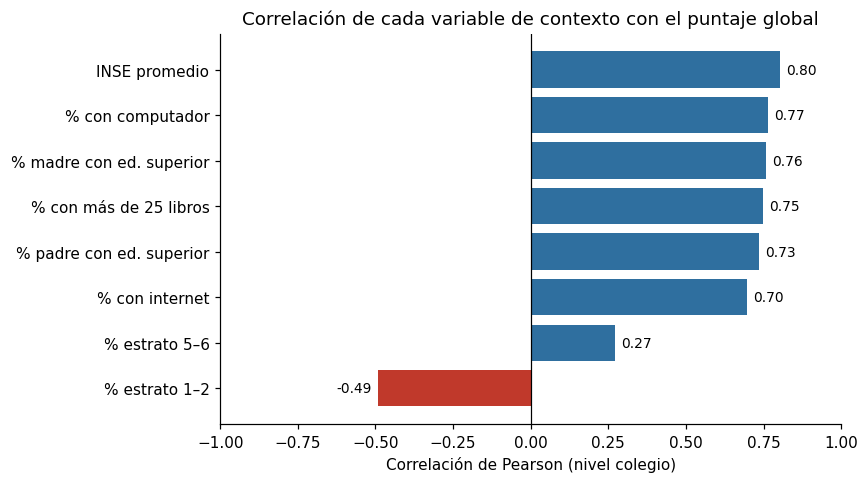

In [5]:
corr = col[[*PERFIL, "punt_global_prom"]].corr()["punt_global_prom"].drop("punt_global_prom")
corr = corr.sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([PERFIL[c] for c in corr.index], corr.values,
        color=[ROJO if v < 0 else AZUL for v in corr.values])
for i, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlim=(-1, 1), title="Correlación de cada variable de contexto con el puntaje global",
       xlabel="Correlación de Pearson (nivel colegio)")
fig.tight_layout()
guardar(fig, "02_correlaciones_contexto")
plt.show()

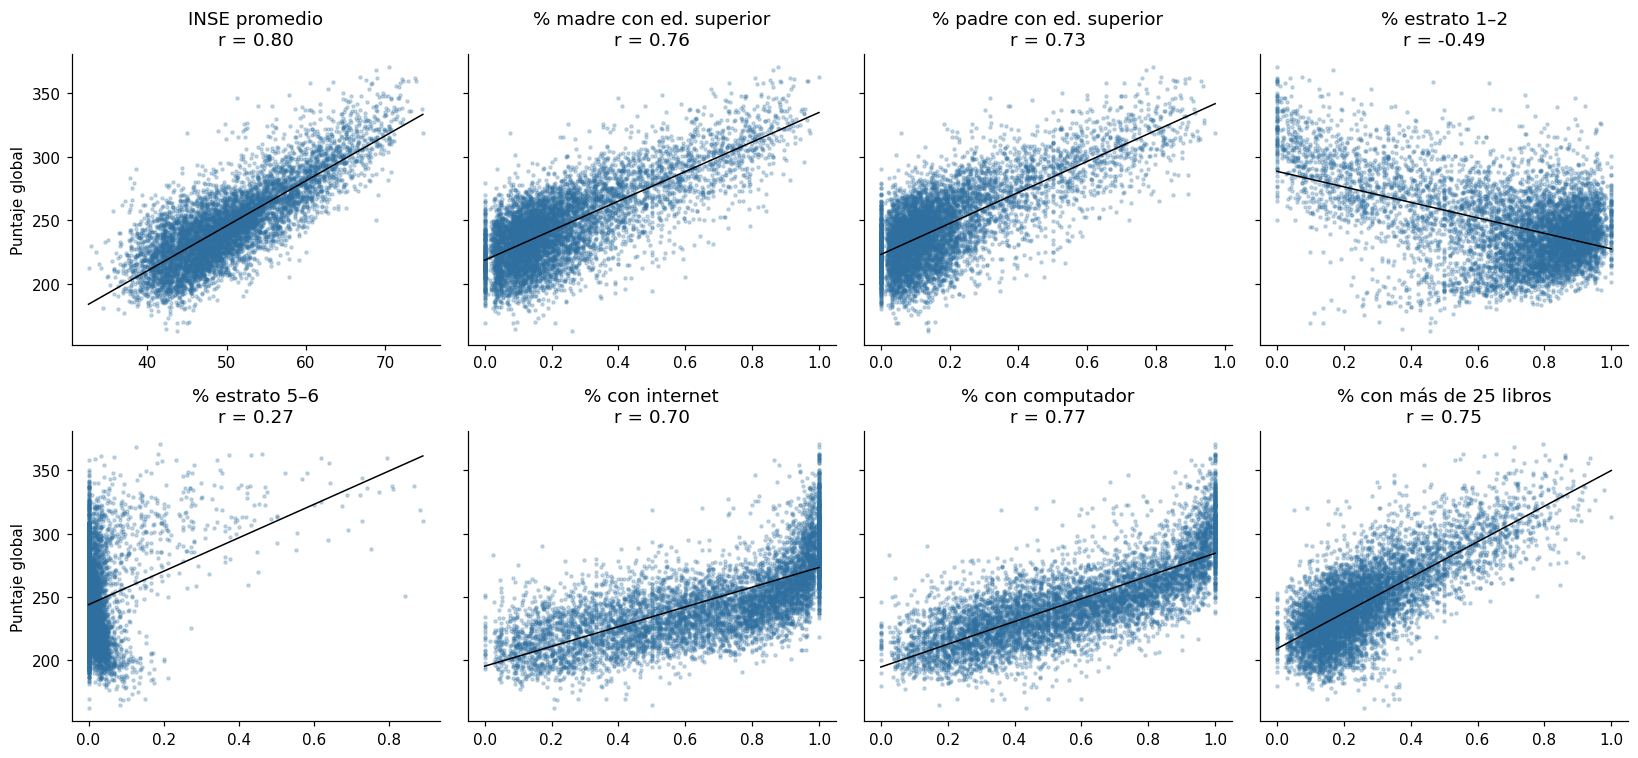

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)
for ax, (c, nombre) in zip(axes.ravel(), PERFIL.items()):
    datos = col[[c, "punt_global_prom"]].dropna()
    ax.scatter(datos[c], datos["punt_global_prom"], s=4, alpha=0.25, color=AZUL)
    m, b = np.polyfit(datos[c], datos["punt_global_prom"], 1)
    xs = np.linspace(datos[c].min(), datos[c].max(), 50)
    ax.plot(xs, m * xs + b, color="black", lw=1)
    ax.set(title=f"{nombre}\nr = {datos.corr().iloc[0, 1]:.2f}", xlabel="")
axes[0, 0].set_ylabel("Puntaje global")
axes[1, 0].set_ylabel("Puntaje global")
fig.tight_layout()
guardar(fig, "03_dispersion_contexto")
plt.show()

In [7]:
# Las variables de contexto están muy relacionadas entre sí (relevante para los modelos lineales)
col[list(PERFIL)].corr().rename(index=PERFIL, columns=PERFIL).round(2)

,INSE promedio,% madre con ed. superior,% padre con ed. superior,% estrato 1–2,% estrato 5–6,% con internet,% con computador,% con más de 25 libros
INSE promedio,1.00,0.89,0.86,-0.71,0.38,0.86,0.91,0.82
% madre con ed. superior,0.89,1.00,0.94,-0.69,0.43,0.64,0.73,0.78
% padre con ed. superior,0.86,0.94,1.00,-0.69,0.47,0.60,0.69,0.77
% estrato 1–2,-0.71,-0.69,-0.69,1.00,-0.47,-0.47,-0.58,-0.67
% estrato 5–6,0.38,0.43,0.47,-0.47,1.00,0.14,0.20,0.40
% con internet,0.86,0.64,0.60,-0.47,0.14,1.00,0.91,0.61
% con computador,0.91,0.73,0.69,-0.58,0.20,0.91,1.00,0.73
% con más de 25 libros,0.82,0.78,0.77,-0.67,0.40,0.61,0.73,1.00


## 4. Puntajes por área

**Qué mirar:** en qué áreas hay más diferencia entre colegios y cuáles dependen más del contexto socioeconómico.

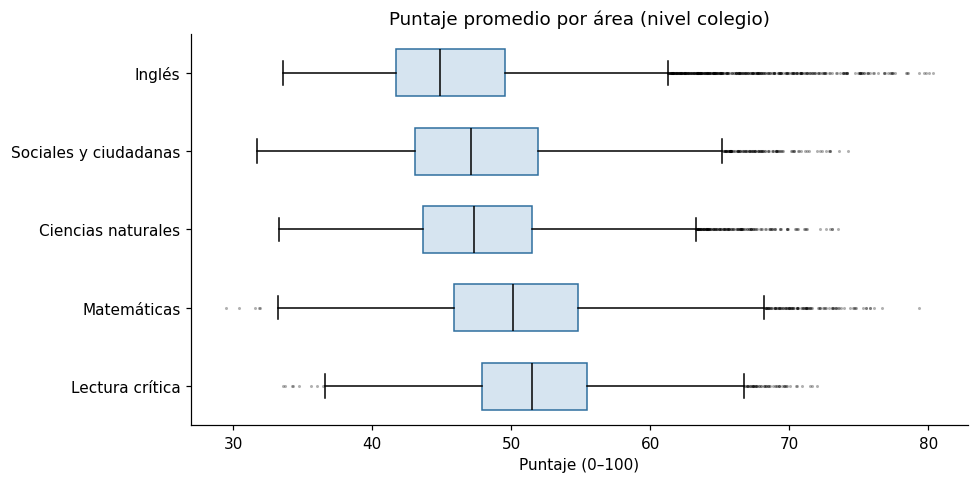

,media,desviacion,corr_con_INSE
Inglés,46.73,7.28,0.85
Sociales y ciudadanas,47.94,6.89,0.81
Lectura crítica,51.85,5.79,0.80
Matemáticas,50.74,6.87,0.76
Ciencias naturales,48.00,6.25,0.75


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
datos_areas = [col[c].dropna() for c in AREAS]
ax.boxplot(datos_areas, vert=False, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#d6e4f0", color=AZUL), medianprops=dict(color="black"),
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
ax.set_yticks(range(1, len(AREAS) + 1), list(AREAS.values()))
ax.set(title="Puntaje promedio por área (nivel colegio)", xlabel="Puntaje (0–100)")
fig.tight_layout()
guardar(fig, "04_puntajes_por_area")
plt.show()

tabla_areas = pd.DataFrame({
    "media": [col[c].mean() for c in AREAS],
    "desviacion": [col[c].std() for c in AREAS],
    "corr_con_INSE": [col[[c, "inse_prom"]].corr().iloc[0, 1] for c in AREAS],
}, index=list(AREAS.values())).round(2)
tabla_areas.sort_values("corr_con_INSE", ascending=False)

## 5. Puntaje según tipo de colegio

**Qué mirar:** las brechas brutas por naturaleza, zona y jornada, antes de tener en cuenta el contexto socioeconómico.

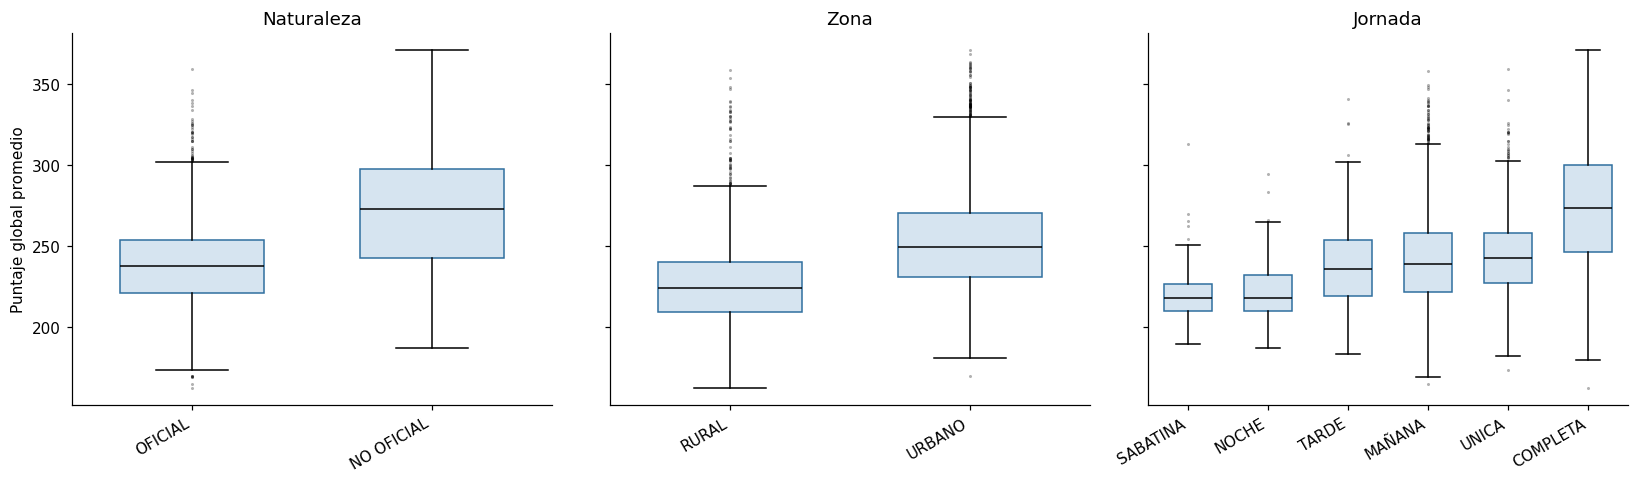

            colegios  media  mediana
naturaleza                          
NO OFICIAL      1936  271.2    272.4
OFICIAL         5051  237.8    237.4 

        colegios  media  mediana
zona                            
URBANO      5377  253.0    249.1
RURAL       1610  227.3    224.0 

          colegios  media  mediana
jornada                           
COMPLETA      1391  272.9    273.2
UNICA         1861  243.2    242.7
MAÑANA        3023  241.5    239.0
TARDE          414  237.3    235.5
NOCHE           64  223.1    218.0
SABATINA       234  219.6    218.0 



In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, var, titulo in zip(axes, ["naturaleza", "zona", "jornada"], ["Naturaleza", "Zona", "Jornada"]):
    orden = col.groupby(var)["punt_global_prom"].median().sort_values().index
    ax.boxplot([col.loc[col[var] == k, "punt_global_prom"] for k in orden], widths=0.6,
               patch_artist=True, boxprops=dict(facecolor="#d6e4f0", color=AZUL),
               medianprops=dict(color="black"), flierprops=dict(marker=".", markersize=2, alpha=0.3))
    ax.set_xticks(range(1, len(orden) + 1), orden, rotation=30, ha="right")
    ax.set_title(titulo)
axes[0].set_ylabel("Puntaje global promedio")
fig.tight_layout()
guardar(fig, "05_puntaje_por_tipo")
plt.show()

for var in ["naturaleza", "zona", "jornada"]:
    print(col.groupby(var)["punt_global_prom"].agg(colegios="size", media="mean", mediana="median")
          .round(1).sort_values("media", ascending=False), "\n")

## 6. Colegios por encima y por debajo de lo esperado

Para ubicar los colegios que se salen de lo esperado se usa una **regresión lineal exploratoria** con las 8 variables del perfil socioeconómico.
No es el modelo final: sirve para ver dónde se concentran las desviaciones. En el reporte, este análisis se repite con el modelo ganador.

- **Residual** = puntaje real − puntaje esperado
- **Por encima:** residual mayor a +1 desviación estándar
- **Por debajo:** residual menor a −1 desviación estándar

In [10]:
X_cols = list(PERFIL)
base = col.dropna(subset=X_cols + ["punt_global_prom"]).copy()

X = np.column_stack([np.ones(len(base)), base[X_cols].to_numpy()])
y = base["punt_global_prom"].to_numpy()
coef, *_ = np.linalg.lstsq(X, y, rcond=None)

base["esperado"] = X @ coef
base["residual"] = y - base["esperado"]
r2 = 1 - (base["residual"] ** 2).sum() / ((y - y.mean()) ** 2).sum()
sd = base["residual"].std()

base["grupo"] = np.select([base["residual"] > sd, base["residual"] < -sd],
                          ["Por encima", "Por debajo"], "Dentro de lo esperado")

print(f"R² del modelo exploratorio con las 8 variables: {r2:.2f}  (solo INSE en la Entrega 1: 0,64)")
print(f"Desviación del residual: {sd:.1f} puntos\n")
print(base["grupo"].value_counts().to_string())

R² del modelo exploratorio con las 8 variables: 0.71  (solo INSE en la Entrega 1: 0,64)
Desviación del residual: 17.1 puntos

grupo
Dentro de lo esperado    4966
Por encima               1021
Por debajo               1000


In [11]:
def formato(t):
    # Residual con 1 decimal y porcentajes de 0 a 100
    t = t.copy()
    t["residual_prom"] = t["residual_prom"].round(1)
    for c in ["pct_por_encima", "pct_por_debajo"]:
        t[c] = (t[c] * 100).round(0)
    return t


def concentracion(var, min_colegios=30):
    t = base.groupby(var).agg(
        colegios=("residual", "size"),
        residual_prom=("residual", "mean"),
        pct_por_encima=("grupo", lambda g: (g == "Por encima").mean()),
        pct_por_debajo=("grupo", lambda g: (g == "Por debajo").mean()),
    )
    t = t[t["colegios"] >= min_colegios].sort_values("residual_prom", ascending=False)
    return formato(t)


print("Referencia: en todo el país ~16 % de los colegios queda en cada extremo.")
concentracion("naturaleza")

Referencia: en todo el país ~16 % de los colegios queda en cada extremo.


,colegios,residual_prom,pct_por_encima,pct_por_debajo
naturaleza,,,,
OFICIAL,5051,1.6,15.0,10.0
NO OFICIAL,1936,-4.1,13.0,25.0


In [12]:
concentracion("zona")

,colegios,residual_prom,pct_por_encima,pct_por_debajo
zona,,,,
RURAL,1610,1.3,17.0,13.0
URBANO,5377,-0.4,14.0,15.0


In [13]:
concentracion("jornada")

,colegios,residual_prom,pct_por_encima,pct_por_debajo
jornada,,,,
UNICA,1861,3.1,15.0,7.0
COMPLETA,1391,2.1,18.0,11.0
MAÑANA,3023,-0.8,15.0,16.0
TARDE,414,-3.6,11.0,20.0
NOCHE,64,-15.6,2.0,48.0
SABATINA,234,-15.9,0.0,47.0


In [14]:
# Cruce naturaleza x zona: residual promedio
pd.crosstab(base["naturaleza"], base["zona"], values=base["residual"], aggfunc="mean").round(1)

zona,RURAL,URBANO
naturaleza,,
NO OFICIAL,-0.3,-4.3
OFICIAL,1.4,1.7


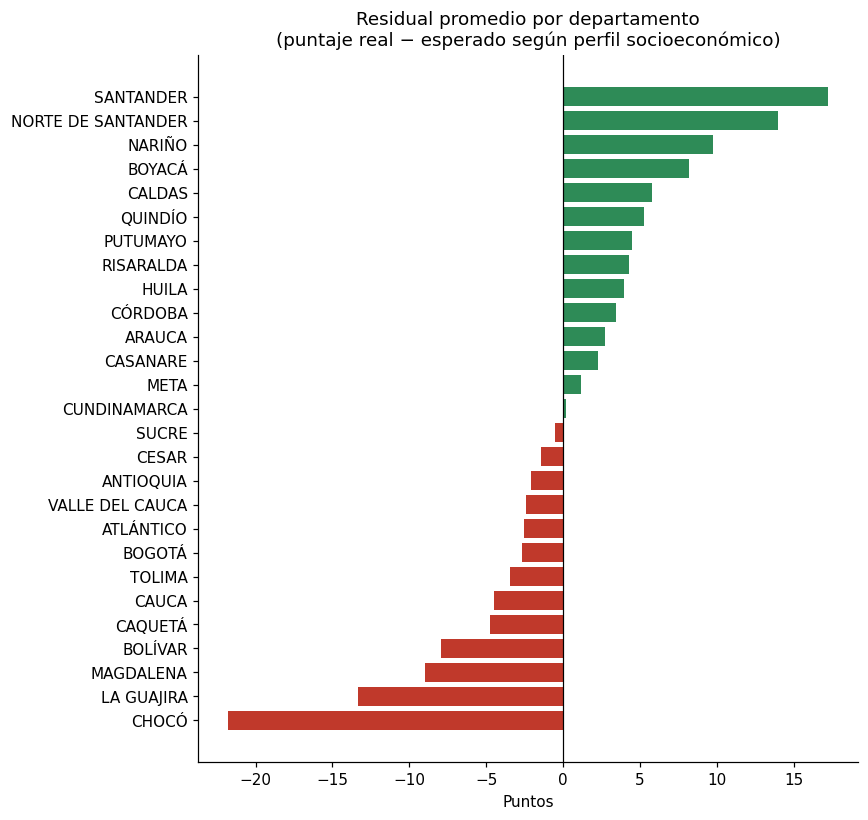

Departamentos con 30 o más colegios: 27


,colegios,residual_prom,pct_por_encima,pct_por_debajo
departamento,,,,
SANTANDER,320,17.2,56.0,4.0
NORTE DE SANTANDER,206,14.0,42.0,5.0
NARIÑO,234,9.8,43.0,16.0
BOYACÁ,234,8.2,26.0,4.0
CALDAS,154,5.8,21.0,5.0
QUINDÍO,85,5.3,16.0,6.0
PUTUMAYO,54,4.5,9.0,7.0
RISARALDA,138,4.2,14.0,4.0
HUILA,190,4.0,15.0,8.0


In [15]:
MIN_COLEGIOS_DEPTO = 30
deptos = (base.groupby("departamento")
          .agg(colegios=("residual", "size"), residual_prom=("residual", "mean"),
               pct_por_encima=("grupo", lambda g: (g == "Por encima").mean()),
               pct_por_debajo=("grupo", lambda g: (g == "Por debajo").mean()))
          .query("colegios >= @MIN_COLEGIOS_DEPTO")
          .sort_values("residual_prom"))

fig, ax = plt.subplots(figsize=(8, max(4, 0.28 * len(deptos))))
ax.barh(deptos.index, deptos["residual_prom"],
        color=[ROJO if v < 0 else VERDE for v in deptos["residual_prom"]])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Residual promedio por departamento\n(puntaje real − esperado según perfil socioeconómico)",
       xlabel="Puntos")
fig.tight_layout()
guardar(fig, "06_residual_por_departamento")
plt.show()

print(f"Departamentos con {MIN_COLEGIOS_DEPTO} o más colegios: {len(deptos)}")
formato(deptos.sort_values("residual_prom", ascending=False))

## 7. Resumen de hallazgos

La siguiente celda imprime las cifras clave. Con ellas, escribe aquí 4–5 conclusiones cortas para el reporte y para la sección de cambios frente a la Entrega 1.

In [16]:
top_corr = corr.abs().sort_values(ascending=False)
area_mas = tabla_areas["corr_con_INSE"].idxmax()
area_menos = tabla_areas["corr_con_INSE"].idxmin()

print(f"- {len(col):,} colegios; puntaje promedio {col['punt_global_prom'].mean():.1f} "
      f"(mediana {col['punt_global_prom'].median():.1f}); mediana de {col['n_evaluados'].median():.0f} evaluados por colegio.")
print(f"- Variables más relacionadas con el puntaje: "
      + ", ".join(f"{PERFIL[c]} (r = {corr[c]:.2f})" for c in top_corr.index[:3]) + ".")
print(f"- Con las 8 variables, una regresión lineal explica el {r2:.0%} de la variación (vs 64 % solo con el INSE).")
print(f"- El área más ligada al contexto es {area_mas} (r = {tabla_areas.loc[area_mas, 'corr_con_INSE']:.2f}); "
      f"la menos ligada, {area_menos} (r = {tabla_areas.loc[area_menos, 'corr_con_INSE']:.2f}).")
mejor, peor = deptos["residual_prom"].idxmax(), deptos["residual_prom"].idxmin()
print(f"- Departamento más por encima de lo esperado: {mejor} ({deptos.loc[mejor, 'residual_prom']:+.1f} puntos); "
      f"más por debajo: {peor} ({deptos.loc[peor, 'residual_prom']:+.1f} puntos).")
nat = base.groupby("naturaleza")["residual"].mean()
print("- Residual promedio por naturaleza: " + ", ".join(f"{k} {v:+.1f}" for k, v in nat.items()) + ".")
print(f"\nGráficas guardadas en: {FIGURAS}")

- 6,987 colegios; puntaje promedio 247.0 (mediana 243.5); mediana de 50 evaluados por colegio.
- Variables más relacionadas con el puntaje: INSE promedio (r = 0.80), % con computador (r = 0.77), % madre con ed. superior (r = 0.76).
- Con las 8 variables, una regresión lineal explica el 71% de la variación (vs 64 % solo con el INSE).
- El área más ligada al contexto es Inglés (r = 0.85); la menos ligada, Ciencias naturales (r = 0.75).
- Departamento más por encima de lo esperado: SANTANDER (+17.2 puntos); más por debajo: CHOCÓ (-21.8 puntos).
- Residual promedio por naturaleza: NO OFICIAL -4.1, OFICIAL +1.6.

Gráficas guardadas en: c:\Users\javie\g3-dsa-proyecto\reports\figures


**Conclusiones**

1. El puntaje promedio por colegio es 247,0 y la mediana 243,5: la distribución tiene una cola de colegios con puntajes altos. La mitad de los colegios tiene 50 evaluados o menos, por lo que sus promedios son más variables.
2. Todas las variables de contexto se relacionan fuertemente con el puntaje (|r| ≥ 0,7), no solo el INSE. Sin embargo, están muy correlacionadas entre sí: juntas explican el 71 % de la variación, frente al 64 % del INSE solo. Esto justifica probar modelos regularizados (Ridge, Lasso).
3. Inglés es el área más ligada al contexto socioeconómico (r = 0,85) y Ciencias naturales la menos (r = 0,75).
4. Con el mismo perfil socioeconómico hay diferencias regionales importantes: Santander queda en promedio 17,2 puntos por encima de lo esperado y Chocó 21,8 por debajo. Por eso el departamento se incluye como variable de entrada del modelo.
5. Al controlar por el perfil socioeconómico, los colegios oficiales quedan levemente por encima de lo esperado (+1,6 puntos) y los no oficiales por debajo (−4,1), aunque en bruto los no oficiales puntúan más alto.